# 02 · Stablecoin de-pegs: USDC in March 2023

**Question.** How far did USDC deviate from $1 around March 10–13, 2023, how long was it off-peg,
and how long did it take to recover? Does the answer depend on the venue (exchange) and the quote
currency?

**Background.** Silicon Valley Bank (SVB) held about $3.3B of the ~$40B of reserves backing USDC.
SVB was closed by regulators on Friday 2023-03-10, and the weekend meant that USDC could not be
redeemed for dollars at Circle until US banks reopened on Monday. With the arbitrage channel
(buy USDC cheap on an exchange → redeem it for $1 at Circle) closed, nothing held the price at $1.

**Data.** 1-minute candles, **2023-03-09 00:00 → 2023-03-14 23:59 UTC**:

| Venue | Pair | Role |
|---|---|---|
| Bitstamp | USDC/USD | main series: USDC priced in dollars |
| Bitstamp | USDT/USD | the "other" stablecoin, also in dollars |
| Binance spot | USDC/USDT | USDC priced in another stablecoin (reopened mid-crisis, see section 2) |

**Conventions.** Everything is in **UTC**. The US switched to daylight saving time on 2023-03-12,
so local US times change offset in the middle of the window: we never convert to local time.
A timestamp is the candle's **open time**: the candle at 07:14 covers [07:14, 07:15).

## 1. Setup and parameters

**Parameters fixed before computing any metric** (lab rule 4: choosing thresholds after seeing
the results is data snooping, because you can always find a threshold that tells the story you want):

- `U = 0.5%`: a candle is **off-peg** if `|close - 1| > U`.
- `HOLD = 3 hours`: USDC has **recovered** only when it is back within `U` and stays there for 3 hours.
- `MIN_TRADED = 30`: those 3 hours must contain at least 30 candles with real trades
  (fixed after the coverage check, before any metric was computed; see section 2).
- `BAND = 0.1%` and the **calm baseline** window 2023-03-09 00:00 → 2023-03-10 12:00 UTC, used to
  measure how tightly the price sits around $1 when arbitrage works.

**One choice changed after inspecting the data (documented, not hidden).** The original plan was
to measure the depth of the de-peg with the candle `low`. After looking at the raw data we saw
isolated extreme prints (single trades far from the rest of the candle) in a thin order book, so
the main price is now `close` for **all** series. `low`/`high` are still reported, as the
"worst traded print", as a sensitivity. Section 5.1 shows the evidence.

**Two more things were added after inspecting the data** (both documented where they are used):
a 15-minute rolling-median sensitivity table (section 5.3), and a fix to the wick classifier
(section 5.1). Neither replaces the main results.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.bitstamp import bitstamp_to_frame, fetch_bitstamp_ohlc, load_or_fetch_json
from src.data.candles import (drop_exact_duplicates, mark_exchange_filled, missing_runs,
                              to_utc, validate_candles)
from src.data.ohlcv import fetch_raw_ohlcv, raw_to_frame
from src import peg_metrics as pm

# ---- Window (UTC) ----
START_UTC = "2023-03-09 00:00"
END_UTC = "2023-03-14 23:59"          # open time of the last 1-minute candle
STEP = pd.Timedelta(minutes=1)

# ---- Parameters fixed before computing metrics (see the markdown above) ----
U = 0.005                              # 0.5% off-peg threshold
HOLD = pd.Timedelta(hours=3)           # recovery must hold this long
MIN_TRADED = 30                        # traded candles required inside the HOLD window
BAND = 0.001                           # 0.1% "calm" band
BASELINE = ("2023-03-09 00:00", "2023-03-10 12:00")  # [start, end) in UTC

# ---- Added AFTER inspecting the data (section 5.3); fixed now, no other windows are tried ----
ROLLING_WINDOW = pd.Timedelta(minutes=15)   # trailing rolling median of close (sensitivity only)

# ---- Plot style (same palette as notebook 01) ----
COLORS = {"Bitstamp USDC/USD": "#2a78d6", "Binance USDC/USDT": "#eb6834",
          "Bitstamp USDT/USD": "#1baf7a", "Bitstamp implied USDC/USDT": "#eda100"}
GRAY = "#52514e"

CACHE_DIR = REPO_ROOT / "data" / "raw" / "02_stablecoin_depegs"
print("Cache folder:", CACHE_DIR.relative_to(REPO_ROOT).as_posix())

Cache folder: data/raw/02_stablecoin_depegs


## 2. Data download & validation

**Bitstamp** (public API, no key). `start`/`end` and the returned timestamps are Unix **seconds**.
Each request returns at most 1,000 candles, so the 8,640 minutes come in 9 requests.
Two things we found while checking the source:

1. When a request covers fewer than `limit` candles, Bitstamp ignores `start` and returns `limit`
   candles *ending* at `end`. This produced overlapping, duplicated candles. The download now sends
   `limit` equal to the exact size of each chunk. As a safety net, identical duplicates are dropped
   and duplicates with **different** values stop the notebook.
2. Bitstamp returns a candle for **every** minute, even when nobody traded. Those candles have
   `volume = 0` and simply repeat the previous close: the exchange forward-fills them for us.
   We keep them, flag them as `filled_by_exchange`, and never treat them as real trades.

**Binance** (via `ccxt`, same download function as notebook 01, now with an end time `until`).
Timestamps are Unix **milliseconds**.

Raw responses are cached in `data/` (gitignored), so re-running the notebook does not download again.

In [2]:
SOURCES = {
    "Bitstamp USDC/USD": ("bitstamp", "usdcusd"),
    "Bitstamp USDT/USD": ("bitstamp", "usdtusd"),
    "Binance USDC/USDT": ("binance", "USDC/USDT"),
}


def load_source(venue, pair):
    # Return (raw row count, DataFrame indexed by open time UTC, timestamp unit).
    if venue == "bitstamp":
        rows = load_or_fetch_json(CACHE_DIR / f"bitstamp_{pair}_1m.json",
                                  lambda: fetch_bitstamp_ohlc(pair, START_UTC, END_UTC))
        return len(rows), bitstamp_to_frame(rows), "s"
    import ccxt  # only needed when the cache is empty
    since_ms = int(to_utc(START_UTC).timestamp() * 1000)   # Binance wants milliseconds
    until_ms = int(to_utc(END_UTC).timestamp() * 1000)
    rows = load_or_fetch_json(
        CACHE_DIR / f"binance_{pair.replace('/', '')}_1m.json",
        lambda: fetch_raw_ohlcv(ccxt.binance({"enableRateLimit": True}), pair, since_ms,
                                timeframe="1m", until=until_ms))
    assert rows[0][0] > 10**11, "expected millisecond timestamps"
    return len(rows), raw_to_frame(rows).drop(columns="timestamp_ms"), "ms"


frames, coverage, gaps = {}, [], {}
for name, (venue, pair) in SOURCES.items():
    n_raw, df, unit = load_source(venue, pair)
    df, n_dup = drop_exact_duplicates(df)            # raises if duplicates disagree
    report = validate_candles(df, START_UTC, END_UTC, step="1min")
    df = mark_exchange_filled(df)
    frames[name] = df
    gaps[name] = report["missing_index"]
    coverage.append({
        "series": name, "timestamp unit": unit,
        "first candle (UTC)": report["first_utc"], "last candle (UTC)": report["last_utc"],
        "received": n_raw, "duplicates dropped": n_dup, "candles": report["candles"],
        "expected": report["expected"], "missing (%)": report["missing_pct"],
        "filled_by_exchange (%)": round(100 * df["filled_by_exchange"].mean(), 1),
    })

coverage = pd.DataFrame(coverage).set_index("series")
coverage

,timestamp unit,first candle (UTC),last candle (UTC),received,duplicates dropped,candles,expected,missing (%),filled_by_exchange (%)
series,,,,,,,,,
Bitstamp USDC/USD,s,2023-03-09 00:00:00+00:00,2023-03-14 23:59:00+00:00,8640,0,8640,8640,0.00,65.0
Bitstamp USDT/USD,s,2023-03-09 00:00:00+00:00,2023-03-14 23:59:00+00:00,8640,0,8640,8640,0.00,60.3
Binance USDC/USDT,ms,2023-03-11 14:00:00+00:00,2023-03-14 23:59:00+00:00,4920,0,4920,8640,43.06,0.0


In [3]:
# Hard checks on exactly what we analyze. Any failure stops the notebook.
for name, df in frames.items():
    assert df.index.is_unique, f"{name}: duplicate timestamps"
    assert df.index.is_monotonic_increasing, f"{name}: not sorted"
    assert (df.index == df.index.floor("1min")).all(), f"{name}: off the 1-minute grid"
    assert str(df.index.tz) == "UTC", f"{name}: not UTC"
    assert df.index.min() >= to_utc(START_UTC) and df.index.max() <= to_utc(END_UTC)
for name in ["Bitstamp USDC/USD", "Bitstamp USDT/USD"]:
    assert len(frames[name]) == 8640, f"{name}: expected 6 days x 1,440 minutes"
    # filled candles really repeat the previous close (the first candle has no previous one)
    f = frames[name]
    assert (f["filled_by_exchange"] & ~f["flat_at_prev_close"]).iloc[1:].sum() == 0
print("All checks passed.")

All checks passed.


### 2.1 Missing candles

Missing minutes are listed as runs of consecutive minutes. **Nothing is filled.**

In [4]:
pd.concat({name: missing_runs(idx) for name, idx in gaps.items()}, names=["series", "run"])

,,first,last,minutes
series,run,,,
Binance USDC/USDT,0,2023-03-09 00:00:00+00:00,2023-03-11 13:59:00+00:00,3720


**Coverage bias (Binance).** Binance closed its USDC/USDT market on 2022-09-26 and reopened it on
**2023-03-11 14:00 UTC**, in the middle of the crisis. Its data therefore **cannot show the trough**,
which happened before the reopening. We do not patch this gap with another source. Instead,
Binance metrics are reported separately and labeled "partial window: trough not observed".
Comparing Binance's "worst price" with Bitstamp's as if they covered the same period would be a
textbook coverage bias: the data looks calmer only because it starts later.

### 2.2 How thin are the books? Share of exchange-filled candles

A filled candle is a minute with **no trades**. A high share means a thin market: few trades,
so a single order can move the printed price.

In [5]:
bitstamp = ["Bitstamp USDC/USD", "Bitstamp USDT/USD"]
filled_by_day = pd.DataFrame({
    name: frames[name]["filled_by_exchange"].groupby(frames[name].index.date).mean() * 100
    for name in bitstamp
}).round(1)
filled_by_day.index.name = "UTC day"
filled_by_day.columns = [f"{c}: filled (%)" for c in filled_by_day.columns]
filled_by_day

,Bitstamp USDC/USD: filled (%),Bitstamp USDT/USD: filled (%)
UTC day,,
2023-03-09,89.7,75.2
2023-03-10,82.2,70.0
2023-03-11,38.1,53.3
2023-03-12,55.1,72.8
2023-03-13,57.6,40.3
2023-03-14,67.2,50.1


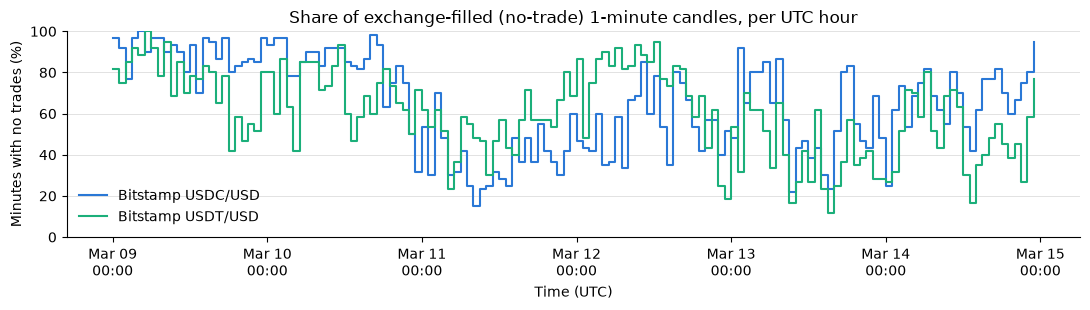

Binance USDC/USDT has no zero-volume candles: 0 of 4920.


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for name in bitstamp:
    hourly = frames[name]["filled_by_exchange"].resample("1h").mean() * 100
    ax.step(hourly.index, hourly, where="post", color=COLORS[name], linewidth=1.5, label=name)
ax.set_ylabel("Minutes with no trades (%)")
ax.set_ylim(0, 100)
ax.set_title("Share of exchange-filled (no-trade) 1-minute candles, per UTC hour")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
ax.grid(axis="y", color="#dddddd", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
ax.set_xlabel("Time (UTC)")
plt.tight_layout()
plt.show()
print("Binance USDC/USDT has no zero-volume candles: "
      f"{int(frames['Binance USDC/USDT']['filled_by_exchange'].sum())} of {len(frames['Binance USDC/USDT'])}.")

## 3. Event timeline (all times approximate, UTC)

In [7]:
EVENTS = pd.DataFrame([
    (1, "2023-03-10 00:00", "2023-03-11 00:00", "Regulators close SVB (date only; time not used)"),
    (2, "2023-03-11 04:25", None, "USDC falls below $0.99 (11:25 PM ET Friday)"),
    (3, "2023-03-11 14:00", None, "Binance reopens USDC/USDT"),
    (4, "2023-03-11 20:54", None, "Circle: any shortfall will be covered with its own resources"),
    (5, "2023-03-12 22:00", "2023-03-13 00:00", "Joint Treasury / Fed / FDIC statement (Sunday evening ET)"),
    (6, "2023-03-13 13:00", None, "US banks open; USDC redemptions resume"),
], columns=["#", "start (UTC, approx.)", "end (UTC, approx.)", "event"]).set_index("#")
for col in ["start (UTC, approx.)", "end (UTC, approx.)"]:
    EVENTS[col] = pd.to_datetime(EVENTS[col], utc=True)
print("Context: Coinbase and Binance paused USDC<->USD conversions over the weekend.")
EVENTS

Context: Coinbase and Binance paused USDC<->USD conversions over the weekend.


,"start (UTC, approx.)","end (UTC, approx.)",event
#,,,
1,2023-03-10 00:00:00+00:00,2023-03-11 00:00:00+00:00,Regulators close SVB (date only; time not used)
2,2023-03-11 04:25:00+00:00,NaT,USDC falls below $0.99 (11:25 PM ET Friday)
3,2023-03-11 14:00:00+00:00,NaT,Binance reopens USDC/USDT
4,2023-03-11 20:54:00+00:00,NaT,Circle: any shortfall will be covered with its...
5,2023-03-12 22:00:00+00:00,2023-03-13 00:00:00+00:00,Joint Treasury / Fed / FDIC statement (Sunday ...
6,2023-03-13 13:00:00+00:00,NaT,US banks open; USDC redemptions resume


## 4. Prices around the event

Each line is the **close** of every 1-minute candle, including exchange-filled ones (which repeat
the last traded close, drawn as flat steps). We do not fill anything ourselves: the Binance line
simply starts when the market reopened. The gray band is ±0.1% around $1; dotted lines mark the
off-peg threshold U = ±0.5%. Numbered markers are the events of section 3 (approximate).

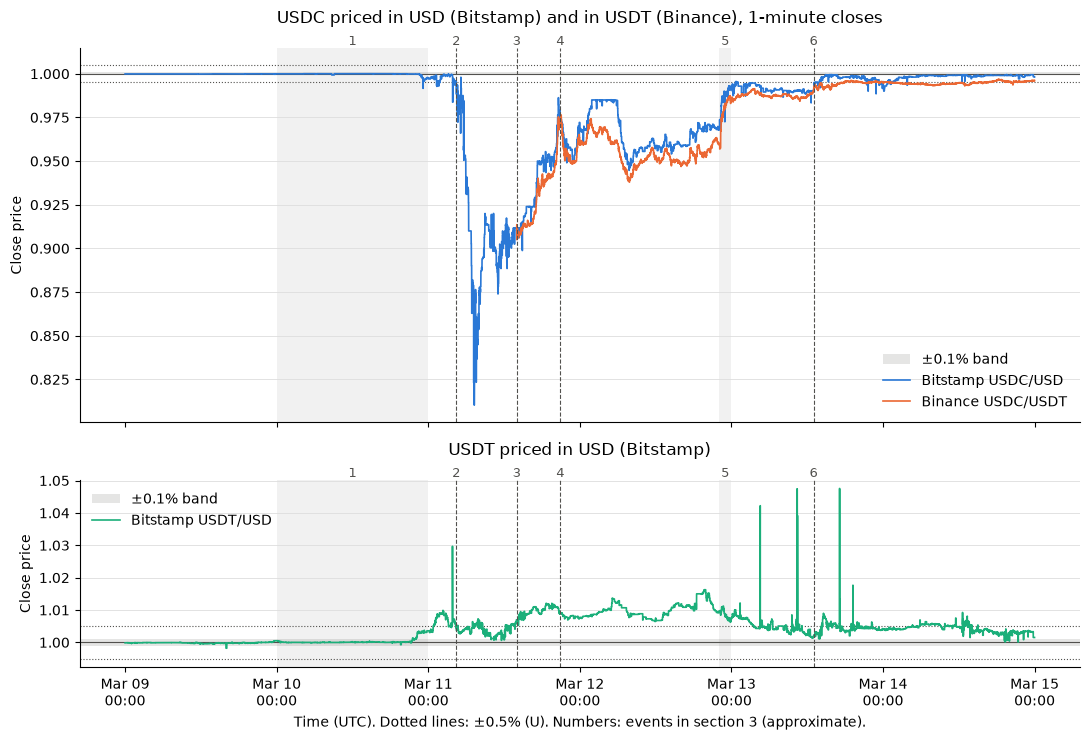

In [8]:
def mark_events(ax, label_y, xmin=None, xmax=None):
    # Only events inside [xmin, xmax] are drawn, so they never stretch the time axis.
    for i, ev in EVENTS.iterrows():
        start, end = ev["start (UTC, approx.)"], ev["end (UTC, approx.)"]
        if (xmin is not None and start < xmin) or (xmax is not None and start > xmax):
            continue
        if pd.isna(end):
            ax.axvline(start, color=GRAY, linestyle="--", linewidth=0.8)
            x = start
        else:
            ax.axvspan(start, end, color=GRAY, alpha=0.08, linewidth=0)
            x = start + (end - start) / 2
        ax.annotate(str(i), (x, label_y), xycoords=("data", "axes fraction"), ha="center",
                    va="bottom", fontsize=9, color=GRAY)


def peg_guides(ax):
    ax.axhspan(1 - BAND, 1 + BAND, color=GRAY, alpha=0.15, linewidth=0, label="±0.1% band")
    ax.axhline(1.0, color=GRAY, linewidth=0.8)
    for level in (1 - U, 1 + U):
        ax.axhline(level, color=GRAY, linestyle=":", linewidth=0.8)


fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, height_ratios=[2, 1])
panels = [["Bitstamp USDC/USD", "Binance USDC/USDT"], ["Bitstamp USDT/USD"]]
for ax, names in zip(axes, panels):
    peg_guides(ax)
    for name in names:
        s = frames[name]["close"]
        ax.step(s.index, s, where="post", color=COLORS[name], linewidth=1.2, label=name)
    mark_events(ax, 1.0)
    ax.set_ylabel("Close price")
    ax.grid(axis="y", color="#dddddd", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right" if len(names) > 1 else "upper left")
axes[0].set_title("USDC priced in USD (Bitstamp) and in USDT (Binance), 1-minute closes", pad=18)
axes[1].set_title("USDT priced in USD (Bitstamp)", pad=18)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
axes[1].set_xlabel("Time (UTC). Dotted lines: ±0.5% (U). Numbers: events in section 3 (approximate).")
plt.tight_layout()
plt.show()

## 5. Metrics

Functions live in `src/peg_metrics.py` (tests in `tests/test_peg_metrics.py`).

- **max deviation** = `min(close) - 1` and its time (main measure, see 5.1 for `low`).
- **minutes off-peg** = minutes with `|close - 1| > U`, each candle counting for one minute of clock
  time. Missing candles count as zero (not observed).
- **off-peg span** = clock time from the first off-peg minute to the end of the last one.
- **time to recovery** = from the trough to the **first** minute where `|close - 1| < U` **and**,
  for the next `HOLD` = 3 h, no *traded* candle leaves the band and at least `MIN_TRADED` = 30
  candles have trades. Measured as the difference between two timestamps (clock time).
  Sensitivity: the same rule counting exchange-filled candles as if they were trades.

### 5.1 Why `close` and not `low`: extreme prints

The `low` of a candle is the single cheapest trade in that minute. In a thin book, one market
order can sweep several price levels and print far below where everybody else is trading. For each
series we list the 5 traded candles whose extreme print (`low` or `high`, whichever is farther from
$1) sticks out the most from the candle's own close, and classify each one:

- **isolated wick**: the median close of the next 15 minutes is closer to the median close of the
  previous 15 minutes than to the extreme (the price went back);
- **level change**: the median close of the next 15 minutes is closer to the extreme (the market
  really moved there and stayed).

This rule is a diagnostic defined **after** looking at the data, not a result. Its first version
compared with the *previous close* only, and mislabeled clusters of consecutive spikes (the previous
close was itself a spike) as level changes; it now uses the median of the 15 minutes before.

**Volume check.** We expected wicks to come from small trades. The candle-level data say the
opposite: the minutes with the biggest wicks have many times the typical traded volume. This fits
a thin book anyway: "thin" means little resting liquidity, so one large market order sweeps several
price levels, producing both a large volume and a deep wick. Limitation: a candle only gives the
volume of the whole minute, not the size of the single trade that printed the extreme.

In [9]:
def top_extreme_prints(df, n=5):
    traded = df[~df["filled_by_exchange"]]
    sticks_out = pd.concat([traded["close"] - traded["low"], traded["high"] - traded["close"]],
                           axis=1).max(axis=1)
    median_volume = traded["volume"].median()
    rows = []
    for ts in sticks_out.nlargest(n).index:
        w = pm.classify_wick(df, ts)
        rows.append({"candle open (UTC)": ts, "open": df.at[ts, "open"], "extreme print": w["extreme"],
                     "close": df.at[ts, "close"], "median close prev 15m": round(w["median_close_before"], 5),
                     "median close next 15m": round(w["median_close_after"], 5),
                     "volume / median traded volume": round(w["volume"] / median_volume, 1),
                     "label": w["label"]})
    return pd.DataFrame(rows)


pd.concat({name: top_extreme_prints(df) for name, df in frames.items()}, names=["series", "rank"])

candle open (UTC)     open  extreme print  \
series            rank                                                     
Bitstamp USDC/USD 0    2023-03-11 06:49:00+00:00  0.89307        0.82093   
                  1    2023-03-11 07:11:00+00:00  0.87890        0.82314   
                  2    2023-03-11 06:50:00+00:00  0.83529        0.83518   
                  3    2023-03-11 07:14:00+00:00  0.83492        0.80526   
                  4    2023-03-11 05:33:00+00:00  0.98456        0.93427   
Bitstamp USDT/USD 0    2023-03-11 03:51:00+00:00  1.00628        1.05000   
                  1    2023-03-13 10:09:00+00:00  1.00398        1.04762   
                  2    2023-03-13 10:23:00+00:00  1.00392        1.04746   
                  3    2023-03-13 10:25:00+00:00  1.00416        1.04699   
                  4    2023-03-13 10:24:00+00:00  1.00415        1.04728   
Binance USDC/USDT 0    2023-03-11 14:00:00+00:00  1.00000        0.88200   
                  1    2023-03-12 22:17:00+00:00  0.95860        0.95690   
                  2    2023-03-11 18:08:00+00:00  0.93980        0.92800   
                  3    2023-03-11 14:02:00+00:00  0.91350        0.90100   
                  4    2023-03-11 20:37:00+00:00  0.97540        0.96800   

                          close  median close prev 15m  median close next 15m  \
series            rank                                                          
Bitstamp USDC/USD 0     0.89407                0.91000                0.87879   
                  1     0.82314                0.87876                0.84590   
                  2     0.89010                0.91000                0.87879   
                  3     0.85740                0.87876                0.85414   
                  4     0.97890                0.98566                0.95163   
Bitstamp USDT/USD 0     1.00631                1.00527                1.00689   
                  1     1.00407                1.00369                1.00436   
                  2     1.04746                1.00419                1.00463   
                  3     1.04699                1.00436                1.00463   
                  4     1.04728                1.00436                1.00463   
Binance USDC/USDT 0     0.91210                1.00000                0.90870   
                  1     0.96750                0.95860                0.97300   
                  2     0.93720                0.93980                0.93630   
                  3     0.90500                0.91285                0.90820   
                  4     0.96960                0.96580                0.97020   

                        volume / median traded volume          label  
series            rank                                                
Bitstamp USDC/USD 0                              30.8  isolated wick  
                  1                              31.0   level change  
                  2                               0.7  isolated wick  
                  3                              34.4  isolated wick  
                  4                              34.4   level change  
Bitstamp USDT/USD 0                              97.3  isolated wick  
                  1                               7.2  isolated wick  
                  2                              61.5  isolated wick  
                  3                              56.8  isolated wick  
                  4                              30.1  isolated wick  
Binance USDC/USDT 0                              15.1   level change  
                  1                              10.8  isolated wick  
                  2                               7.2  isolated wick  
                  3                              16.1  isolated wick  
                  4                               8.1   level change

### 5.2 Metrics per series

The implied cross **USDC/USDT = (USDC/USD) / (USDT/USD)** uses the two Bitstamp series at the same
minute (section 6 explains it). A minute of the implied cross counts as "traded" only if **both**
Bitstamp candles had trades.

In [10]:
usdc, usdt = frames["Bitstamp USDC/USD"], frames["Bitstamp USDT/USD"]
implied = pd.DataFrame({"close": pm.implied_cross(usdc["close"], usdt["close"]),
                        "low": pm.implied_cross(usdc["low"], usdt["high"]),   # worst case for USDC
                        "high": pm.implied_cross(usdc["high"], usdt["low"])})
implied["filled_by_exchange"] = usdc["filled_by_exchange"] | usdt["filled_by_exchange"]
series_all = {**frames, "Bitstamp implied USDC/USDT": implied}


def peg_metrics_table(df, trough="low side"):
    close = df["close"]
    traded = ~df["filled_by_exchange"]
    if trough == "low side":
        dev, t_dev = pm.max_deviation(close)
        worst, t_worst = pm.max_deviation(df.loc[traded, "low"])
    else:                                   # for USDT: biggest move in either direction
        down, t_down = pm.max_deviation(close)
        up, t_up = pm.max_upside_deviation(close)
        dev, t_dev = (up, t_up) if abs(up) > abs(down) else (down, t_down)
        w_lo, t_lo = pm.max_deviation(df.loc[traded, "low"])
        w_hi, t_hi = pm.max_upside_deviation(df.loc[traded, "high"])
        worst, t_worst = (w_hi, t_hi) if abs(w_hi) > abs(w_lo) else (w_lo, t_lo)
    first_off, last_off_end, span = pm.off_peg_span(close, U)
    t_rec, d_rec = pm.time_to_recovery(close, t_dev, U, HOLD, traded=traded, min_traded=MIN_TRADED)
    t_rec_f, d_rec_f = pm.time_to_recovery(close, t_dev, U, HOLD, traded=None, min_traded=MIN_TRADED)
    base = close.loc[to_utc(BASELINE[0]): to_utc(BASELINE[1]) - STEP]
    return {
        "max deviation of close (%)": round(100 * dev, 2),
        "time of max deviation (UTC)": t_dev,
        "worst traded print, low/high (%)": round(100 * worst, 2),
        "time of worst traded print (UTC)": t_worst,
        "minutes off-peg (|close-1| > 0.5%)": pm.minutes_off_peg(close, U),
        "traded candles off-peg (count)": int(pm.is_off_peg(close[traded], U).sum()),
        "first off-peg minute (UTC)": first_off,
        "off-peg span (h)": round(span / pd.Timedelta(hours=1), 1),
        "recovery time (UTC), traded candles": t_rec,
        "time to recovery (h), traded candles": round(d_rec / pd.Timedelta(hours=1), 1) if pd.notna(d_rec) else None,
        "time to recovery (h), filled candles included": round(d_rec_f / pd.Timedelta(hours=1), 1) if pd.notna(d_rec_f) else None,
        "baseline: minutes within ±0.1% (%)": round(100 * pm.share_in_band(base, BAND), 1) if len(base) else None,
    }


results_bitstamp = pd.DataFrame({
    "Bitstamp USDC/USD": peg_metrics_table(series_all["Bitstamp USDC/USD"]),
    "Bitstamp USDT/USD": peg_metrics_table(series_all["Bitstamp USDT/USD"], trough="either side"),
    "Bitstamp implied USDC/USDT": peg_metrics_table(series_all["Bitstamp implied USDC/USDT"]),
})
results_bitstamp

,Bitstamp USDC/USD,Bitstamp USDT/USD,Bitstamp implied USDC/USDT
max deviation of close (%),-18.97,4.75,-19.43
time of max deviation (UTC),2023-03-11 07:17:00+00:00,2023-03-13 17:07:00+00:00,2023-03-11 07:17:00+00:00
"worst traded print, low/high (%)",-19.47,5.0,-19.84
time of worst traded print (UTC),2023-03-11 07:14:00+00:00,2023-03-11 03:50:00+00:00,2023-03-11 07:14:00+00:00
minutes off-peg (|close-1| > 0.5%),3528.0,3250.0,5298.0
traded candles off-peg (count),1784,1261,1310
first off-peg minute (UTC),2023-03-10 23:11:00+00:00,2023-03-11 00:48:00+00:00,2023-03-10 22:58:00+00:00
off-peg span (h),85.3,86.2,95.5
"recovery time (UTC), traded candles",2023-03-13 14:10:00+00:00,2023-03-13 22:19:00+00:00,2023-03-14 16:45:00+00:00
"time to recovery (h), traded candles",54.9,5.2,81.5


In [11]:
# Binance is NOT comparable column-by-column with Bitstamp: it starts after the trough.
results_binance = pd.DataFrame({
    "Binance USDC/USDT (partial window: trough not observed)": peg_metrics_table(frames["Binance USDC/USDT"]),
})
results_binance.loc["first candle (UTC)"] = frames["Binance USDC/USDT"].index.min()
results_binance.loc["baseline: minutes within ±0.1% (%)"] = "not observed (market closed)"
results_binance

,Binance USDC/USDT (partial window: trough not observed)
max deviation of close (%),-9.5
time of max deviation (UTC),2023-03-11 14:02:00+00:00
"worst traded print, low/high (%)",-11.8
time of worst traded print (UTC),2023-03-11 14:00:00+00:00
minutes off-peg (|close-1| > 0.5%),4044.0
traded candles off-peg (count),4044
first off-peg minute (UTC),2023-03-11 14:00:00+00:00
off-peg span (h),78.6
"recovery time (UTC), traded candles",2023-03-14 16:42:00+00:00
"time to recovery (h), traded candles",74.7


### 5.3 Sensitivity: 15-minute rolling median (added after inspecting the data)

**This section was added after inspecting the data.** Section 5.1 showed that in USDT/USD even
some *closes* are one-minute spikes, so the main table's USDT "max deviation" and "time to recovery"
are driven by single prints (see Limitations). To see how much each conclusion depends on such
spikes, we recompute the same metrics on the **trailing 15-minute rolling median** of the close,
for **every** series, with exactly the same thresholds. The 15-minute window was fixed once and no
other windows were tried (trying several and keeping the nicest would be data snooping).

The median at minute *t* uses only minutes *t − 14 … t*: no future data. It ignores spikes shorter
than ~7 minutes and follows moves that last. **The main table above remains the main result**;
this one is only a sensitivity check.

In [12]:
def smoothed(df):
    out = df.copy()
    out["close"] = pm.rolling_median_close(df["close"], ROLLING_WINDOW)
    return out


sens_rows = [r for r in results_bitstamp.index if "worst traded print" not in r]
results_sensitivity = pd.DataFrame({
    "Bitstamp USDC/USD": peg_metrics_table(smoothed(series_all["Bitstamp USDC/USD"])),
    "Bitstamp USDT/USD": peg_metrics_table(smoothed(series_all["Bitstamp USDT/USD"]), trough="either side"),
    "Bitstamp implied USDC/USDT": peg_metrics_table(smoothed(series_all["Bitstamp implied USDC/USDT"])),
    "Binance USDC/USDT (partial window: trough not observed)": peg_metrics_table(smoothed(frames["Binance USDC/USDT"])),
}).loc[sens_rows]
results_sensitivity

,Bitstamp USDC/USD,Bitstamp USDT/USD,Bitstamp implied USDC/USDT,Binance USDC/USDT (partial window: trough not observed)
max deviation of close (%),-16.51,1.63,-16.89,-9.25
time of max deviation (UTC),2023-03-11 07:20:00+00:00,2023-03-12 19:51:00+00:00,2023-03-11 07:20:00+00:00,2023-03-11 14:21:00+00:00
minutes off-peg (|close-1| > 0.5%),3504.0,3230.0,5329.0,4042.0
traded candles off-peg (count),1771,1240,1317,4042
first off-peg minute (UTC),2023-03-11 01:45:00+00:00,2023-03-11 00:55:00+00:00,2023-03-10 23:05:00+00:00,2023-03-11 14:00:00+00:00
off-peg span (h),71.7,84.9,95.5,78.8
"recovery time (UTC), traded candles",2023-03-13 14:05:00+00:00,2023-03-13 10:30:00+00:00,2023-03-14 16:45:00+00:00,2023-03-14 16:44:00+00:00
"time to recovery (h), traded candles",54.8,14.7,81.4,74.4
"time to recovery (h), filled candles included",54.8,14.7,81.1,74.4
baseline: minutes within ±0.1% (%),100.0,100.0,100.0,None


## 6. Venue & quote comparison

A price always belongs to a venue **and** a quote currency. "USDC/USDT" measures USDC in units of
another stablecoin: if USDT itself moves away from $1, USDC/USDT and USDC/USD tell different stories.
From Bitstamp we can build the **implied** cross:

$$\text{USDC/USDT}_{\text{implied}} = \frac{\text{USDC/USD}}{\text{USDT/USD}}$$

and compare it, minute by minute, with the **real** USDC/USDT traded on Binance — only where both
exist (from Binance's reopening on). The difference is measured in **basis points** (bps):
1 bp = 0.01%, so 100 bps = 1%.

In [13]:
binance = frames["Binance USDC/USDT"]
overlap = pd.concat({"implied (Bitstamp)": implied["close"], "Binance": binance["close"],
                     "both Bitstamp candles traded": ~implied["filled_by_exchange"]},
                    axis=1, join="inner")
overlap["Binance - implied (bps)"] = (overlap["Binance"] - overlap["implied (Bitstamp)"]) * 1e4

summary = {}
for label, rows in {"all overlapping minutes": overlap,
                    "only minutes where both Bitstamp candles traded": overlap[overlap["both Bitstamp candles traded"]]}.items():
    d = rows["Binance - implied (bps)"]
    summary[label] = {"minutes": len(d), "median (bps)": d.median(), "mean (bps)": d.mean(),
                      "median |diff| (bps)": d.abs().median(), "95th pct |diff| (bps)": d.abs().quantile(0.95),
                      "max |diff| (bps)": d.abs().max()}
print(f"Overlap: {overlap.index.min()} -> {overlap.index.max()}")
pd.DataFrame(summary).round(1)

Overlap: 2023-03-11 14:00:00+00:00 -> 2023-03-14 23:59:00+00:00


,all overlapping minutes,only minutes where both Bitstamp candles traded
minutes,4920.0,1071.0
median (bps),4.5,4.8
mean (bps),3.9,7.9
median |diff| (bps),9.8,10.6
95th pct |diff| (bps),79.4,72.2
max |diff| (bps),420.6,412.3


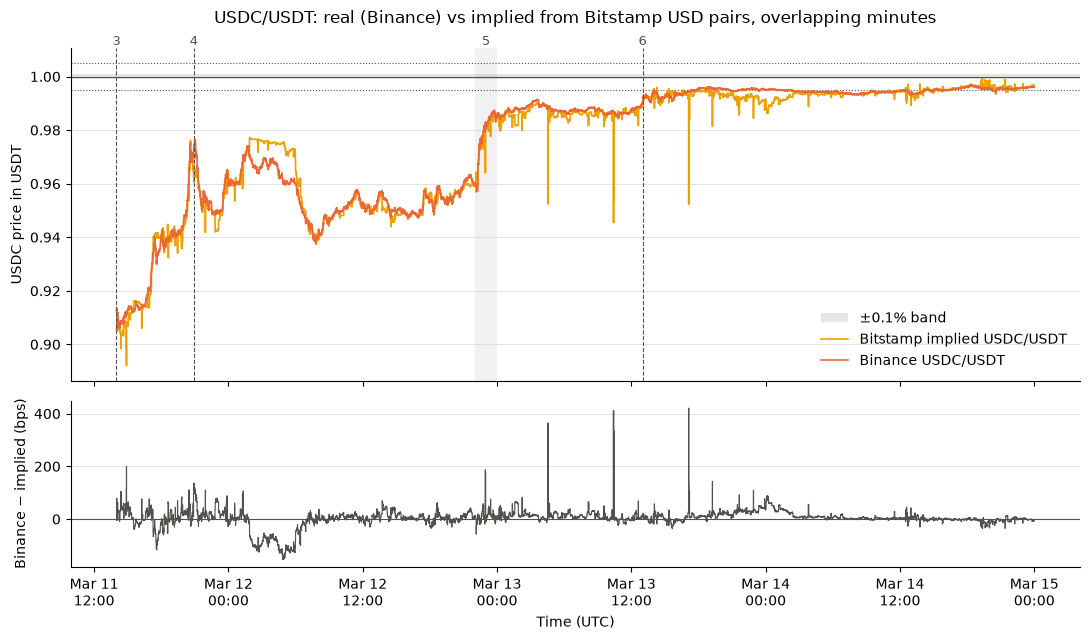

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[2, 1])
ax = axes[0]
peg_guides(ax)
for name, s in [("Bitstamp implied USDC/USDT", overlap["implied (Bitstamp)"]),
                ("Binance USDC/USDT", overlap["Binance"])]:
    ax.step(s.index, s, where="post", color=COLORS[name], linewidth=1.2, label=name)
mark_events(ax, 1.0, xmin=overlap.index.min(), xmax=overlap.index.max())
ax.set_ylabel("USDC price in USDT")
ax.set_title("USDC/USDT: real (Binance) vs implied from Bitstamp USD pairs, overlapping minutes", pad=18)
ax.legend(frameon=False, loc="lower right")
ax = axes[1]
ax.axhline(0, color=GRAY, linewidth=0.8)
ax.step(overlap.index, overlap["Binance - implied (bps)"], where="post", color=GRAY, linewidth=0.8)
ax.set_ylabel("Binance − implied (bps)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
ax.set_xlabel("Time (UTC)")
for a in axes:
    a.grid(axis="y", color="#dddddd", linewidth=0.6)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 6.1 Did USDT move above or below $1?

In [15]:
usdt_close = usdt["close"]
rows = {}
for label, (a, b) in {"calm baseline": BASELINE,
                      "crisis (Mar 11 00:00 -> Mar 13 13:00)": ("2023-03-11 00:00", "2023-03-13 13:00"),
                      "after (Mar 13 13:00 -> end)": ("2023-03-13 13:00", "2023-03-15 00:00")}.items():
    s = usdt_close.loc[to_utc(a): to_utc(b) - STEP]
    rows[label] = {"median close": s.median(), "min close": s.min(), "max close": s.max(),
                   "minutes above 1 + 0.1% (%)": 100 * (pm.abs_deviation(s).where(s > 1, 0) > BAND).mean(),
                   "minutes below 1 - 0.1% (%)": 100 * (pm.abs_deviation(s).where(s < 1, 0) > BAND).mean()}
pd.DataFrame(rows).round(4)

,calm baseline,crisis (Mar 11 00:00 -> Mar 13 13:00),after (Mar 13 13:00 -> end)
median close,0.9999,1.0078,1.0042
min close,0.9982,1.0006,1.0001
max close,1.0005,1.0475,1.0476
minutes above 1 + 0.1% (%),0.0000,99.7268,98.8095
minutes below 1 - 0.1% (%),0.3241,0.0000,0.0000


## 7. Results, limitations and key takeaways

### 7.1 Results table

Main measure: `close`. Bitstamp columns cover the full window; Binance is kept apart because
its window starts after the trough.

In [16]:
headline = [
    "max deviation of close (%)", "time of max deviation (UTC)",
    "worst traded print, low/high (%)", "minutes off-peg (|close-1| > 0.5%)",
    "off-peg span (h)", "time to recovery (h), traded candles",
    "time to recovery (h), filled candles included", "baseline: minutes within ±0.1% (%)",
]
print("Main results (close):")
display(results_bitstamp.loc[headline])
display(results_binance.loc[headline])
print("Sensitivity only (15-minute rolling median of close, added after inspecting the data):")
display(results_sensitivity.loc[[r for r in headline if r in results_sensitivity.index]])

Main results (close):


,Bitstamp USDC/USD,Bitstamp USDT/USD,Bitstamp implied USDC/USDT
max deviation of close (%),-18.97,4.75,-19.43
time of max deviation (UTC),2023-03-11 07:17:00+00:00,2023-03-13 17:07:00+00:00,2023-03-11 07:17:00+00:00
"worst traded print, low/high (%)",-19.47,5.0,-19.84
minutes off-peg (|close-1| > 0.5%),3528.0,3250.0,5298.0
off-peg span (h),85.3,86.2,95.5
"time to recovery (h), traded candles",54.9,5.2,81.5
"time to recovery (h), filled candles included",54.9,5.2,81.2
baseline: minutes within ±0.1% (%),100.0,99.7,99.7


,Binance USDC/USDT (partial window: trough not observed)
max deviation of close (%),-9.5
time of max deviation (UTC),2023-03-11 14:02:00+00:00
"worst traded print, low/high (%)",-11.8
minutes off-peg (|close-1| > 0.5%),4044.0
off-peg span (h),78.6
"time to recovery (h), traded candles",74.7
"time to recovery (h), filled candles included",74.7
baseline: minutes within ±0.1% (%),not observed (market closed)


Sensitivity only (15-minute rolling median of close, added after inspecting the data):


,Bitstamp USDC/USD,Bitstamp USDT/USD,Bitstamp implied USDC/USDT,Binance USDC/USDT (partial window: trough not observed)
max deviation of close (%),-16.51,1.63,-16.89,-9.25
time of max deviation (UTC),2023-03-11 07:20:00+00:00,2023-03-12 19:51:00+00:00,2023-03-11 07:20:00+00:00,2023-03-11 14:21:00+00:00
minutes off-peg (|close-1| > 0.5%),3504.0,3230.0,5329.0,4042.0
off-peg span (h),71.7,84.9,95.5,78.8
"time to recovery (h), traded candles",54.8,14.7,81.4,74.4
"time to recovery (h), filled candles included",54.8,14.7,81.1,74.4
baseline: minutes within ±0.1% (%),100.0,100.0,100.0,None


### 7.2 Limitations

- **Coverage bias (Binance):** USDC/USDT reopened on 2023-03-11 14:00 UTC, after the trough.
  Its "worst price" is the worst price *after reopening*, not the worst price of the crisis.
- **USDT/USD metrics in the main table are not interpretable as "the USDT de-peg".** Its
  "max deviation of close" comes from a single minute whose close spiked (an isolated print in a
  thin book, section 5.1), and its "time to recovery" is measured from that spike, which happened
  on Monday afternoon, after the crisis. The method was fixed in advance and applied equally to all
  series, so we keep the numbers, but USDT's real behavior is a **sustained premium** above $1:
  see section 6.1 and the rolling-median sensitivity in section 5.3.
- **Wick volume:** the biggest wicks happen in high-volume minutes, not small ones (section 5.1).
  We cannot see the size of the single trade behind each extreme print.
- **Post-hoc choices** (made after inspecting the data, all documented): `close` instead of `low`,
  the 15-minute rolling-median sensitivity, and the wick classifier using the median of the
  previous 15 minutes.
- **One exchange per pair:** USDC/USD and USDT/USD come only from Bitstamp. Other venues
  (Coinbase, Kraken, Curve) traded at different prices during the weekend.
- **Thin book:** about 65% of USDC/USD minutes on Bitstamp had no trades at all (60% for USDT/USD).
  A few trades can set the printed price, which is why we use `close` and report `low`/`high` apart.
- **1-minute candles:** they hide what happens inside the minute (and the size of the single trade
  behind a wick).
- **Thresholds:** U = 0.5%, HOLD = 3 h and MIN_TRADED = 30 were fixed in advance, but they are still
  choices: other values give other durations.
- **Event times are approximate**, and the SVB closure is drawn as a whole day.

### 7.3 Key takeaways

1. **How far.** On Bitstamp, USDC/USD closed as low as **0.8103 (−18.97%) at 2023-03-11 07:17 UTC**,
   Saturday early morning, while redemptions were closed. The single worst trade was 0.8053 and lasted
   less than a minute; the 15-minute rolling median bottoms at −16.5%. The *depth* of a de-peg depends
   on how it is measured; the durations below do not.
2. **How long, and what ended it.** USDC/USD was off-peg (|close − 1| > 0.5%) for **3,528 minutes
   (~59 h)** and recovered for good at **2023-03-13 14:10 UTC**, **54.9 h after the trough** and about
   an hour after US banks opened and redemptions resumed. The Sunday-evening government statement
   lifted it to ~0.99, but only working redemption (and the arbitrage it allows) closed the last gap.
   The result barely moves with exchange-filled candles included (54.9 h) or with the rolling median (54.8 h).
3. **The quote currency matters.** USDT traded at a **premium**: a median of **+0.78%** during the crisis
   and +0.42% afterwards. So USDC priced in USDT recovered only on **2023-03-14 ~16:45 UTC**, about
   **27 h later** than in dollars, both in the implied Bitstamp cross (16:45) and in Binance's real
   market (16:42).
4. **Venues mostly agree, until moving money is hard.** The real (Binance) and implied (Bitstamp)
   USDC/USDT prices typically differ by ~10 bps, but they stayed ~1% apart for hours early on March 12,
   when moving dollars or USDC between exchanges was slow and risky: the no-arbitrage band widens.
5. **Coverage bias is easy to miss.** Binance reopened USDC/USDT at 2023-03-11 14:00 UTC, after the
   trough. Its worst close (−9.5%) is half of Bitstamp's: not a calmer market, just a later start.